# Module 3 — Classification: Course Lead Scoring

**Course:** ML Zoomcamp 2026
**Dataset:** [2026 Lead Scoring dataset](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)
**Homework spec:** [homework.md](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/03-classification/homework.md)
**Author:** Somasekhar Reddy  **Date:** 05/10/2026

## Goal
Predict whether a lead **signs up to the platform** (`converted` = 1) or not (`converted` = 0), using logistic regression on lead information such as source, industry, income and engagement.

## Outline
1. **Setup** — imports and loading data
2. **Data preparation & EDA** — structure, missing values, target balance, filling NAs
3. **Q1** — Most frequent `industry`
4. **Q2** — Correlation between numerical features
5. **Split the data** — 60% train / 20% validation / 20% test
6. **Q3** — Mutual information of categorical features
7. **Q4** — Logistic regression with one-hot encoding
8. **Q5** — Feature elimination
9. **Q6** — Regularization (`C`)
10. **Summary of answers**

# 1. Setup

## 1.1 Imports

In [1]:
# Basic imports
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: splitting, encoding, model, metrics
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, accuracy_score

# Display helpers (render nice headings/tables inside a single cell)
from IPython.display import display, Markdown

# Show every column when printing a DataFrame (no "..." truncation)
pd.set_option('display.max_columns', None)

## 1.2 Import Data

In [2]:
# Load the pinned 2026 release of the dataset directly from GitHub
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)

# 2. Data preparation & EDA

Before modelling we want to know the size of the data, which columns are categorical vs. numerical, where values are missing, and how balanced the target is.

## 2.1 Structure, dtypes and missing values

In [3]:
# Check the top 5 rows -> quick sanity check that the data loaded correctly
display(Markdown("### Head"))
display(df.head())

# Dataset size (rows, columns)
display(Markdown("### Shape"))
print(df.shape)

# Data types of the columns
# -> text columns are categorical (need one-hot encoding later),
#    the rest are numerical
display(Markdown("### Data Types"))
display(df.dtypes)

# Count missing values per column
# -> several columns have NaNs, in both categorical and numerical features
display(Markdown("### Missing Values"))
display(df.isnull().sum())

### Head

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


### Shape

(5000, 9)


### Data Types

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

### Missing Values

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
# Define the target and split the remaining columns into categorical / numerical.
# Listing them explicitly is more robust than relying on dtype detection
# (newer pandas versions use a dedicated string dtype instead of 'object').
target = "converted"
categorical = ["lead_source", "industry", "employment_status", "location"]
numerical = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

print("categorical:", categorical)
print("numerical:  ", numerical)

categorical: ['lead_source', 'industry', 'employment_status', 'location']
numerical:   ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


## 2.2 Target variable: how balanced is `converted`?

converted
1    0.577
0    0.423
Name: proportion, dtype: float64

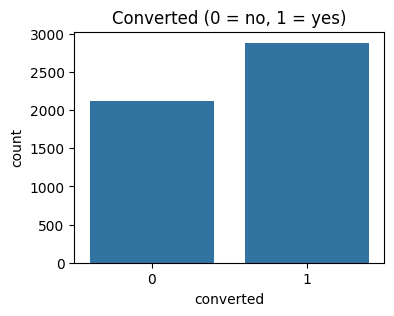

In [5]:
# Share of each class. Heavily imbalanced data would make plain accuracy misleading.
display(df[target].value_counts(normalize=True).round(3))

plt.figure(figsize=(4, 3))
sns.countplot(x=df[target])
plt.title("Converted (0 = no, 1 = yes)")
plt.show()

**Observation:** the classes are only mildly imbalanced (about 58% converted vs. 42% not converted). A model that always predicts "converted" would already reach ≈ 0.58 accuracy on the full data (≈ 0.60 on our validation split), so that is the baseline to beat.

## 2.3 Distribution of the numerical features

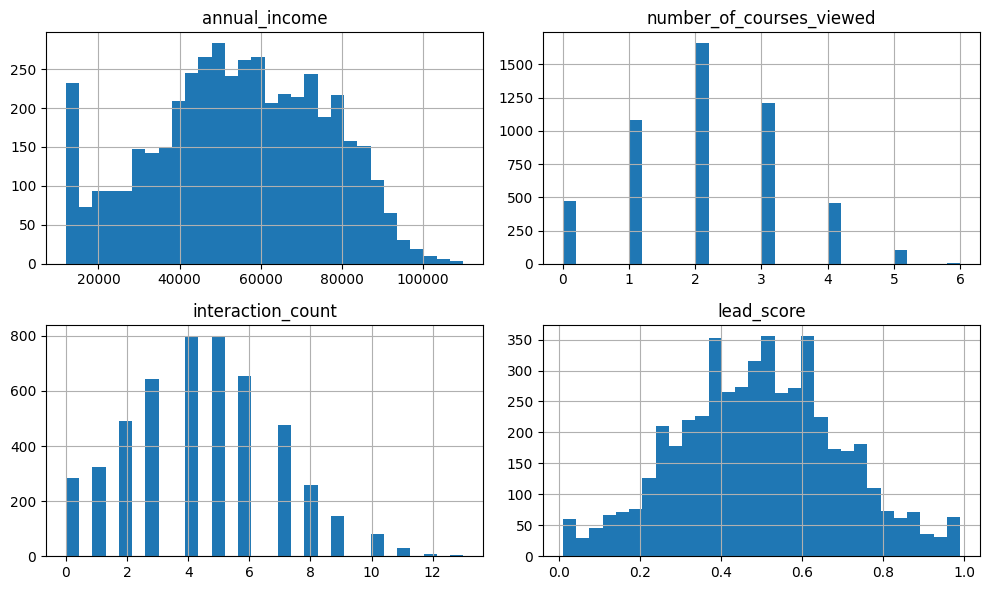

In [6]:
# Histograms of the numerical features to spot skew, outliers and odd values
df[numerical].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 2.4 Fill the missing values

As the homework instructs:
- **categorical** features -> replace missing values with the string `'NA'`
- **numerical** features -> replace missing values with `0.0`

In [7]:
# Fill categorical NaNs with the explicit category 'NA'
df[categorical] = df[categorical].fillna("NA")

# Fill numerical NaNs with 0.0
df[numerical] = df[numerical].fillna(0.0)

# Verify: no missing values should remain
print("Remaining missing values:", int(df.isnull().sum().sum()))

Remaining missing values: 0


# 3. Question 1 — Most frequent `industry`

The mode is the most common value. We compute it **after** filling NAs, so `'NA'` competes as a regular category.

In [8]:
display(df["industry"].value_counts())
print("Q1 answer (mode of industry):", df["industry"].mode()[0])

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

Q1 answer (mode of industry): technology


# 4. Question 2 — Correlation matrix of the numerical features

We look at the pairwise correlation of the numerical features and, as the question says, only compare the four listed pairs.

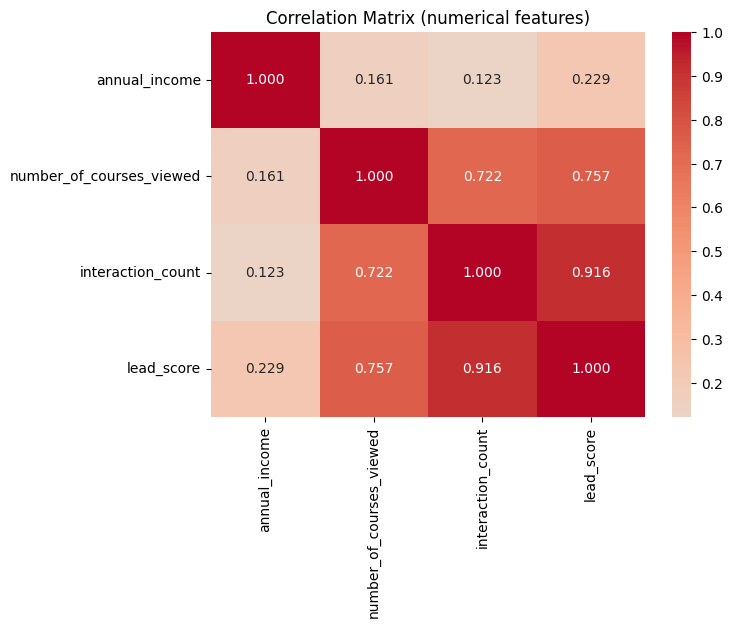

In [9]:
# Correlation matrix of the numerical features
corr = df[numerical].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (numerical features)")
plt.show()

In [10]:
# Only the pairs listed in the question
pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

pair_corr = {f"{a} & {b}": corr.loc[a, b] for a, b in pairs}
pair_corr = pd.Series(pair_corr)
display(pair_corr.round(4))

# "Biggest" = largest correlation (we compare the signed values; check abs() too)
print("Q2 answer:", pair_corr.idxmax())
print("Same with abs():", pair_corr.abs().idxmax())

interaction_count & lead_score                  0.9157
number_of_courses_viewed & lead_score           0.7572
number_of_courses_viewed & interaction_count    0.7216
annual_income & interaction_count               0.1228
dtype: float64

Q2 answer: interaction_count & lead_score
Same with abs(): interaction_count & lead_score


# 5. Split the data

We use the **exact** calls from the homework: 80% / 20% for full-train / test, then split full-train 75% / 25%, giving **60% train / 20% validation / 20% test**. The target is removed from the feature DataFrames so the model can't see it.

In [11]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

# Reset indices for cleanliness (not strictly needed)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Extract the target vectors...
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

# ...and make sure the target is NOT in the feature DataFrames
# (df_full_train is kept untouched; we are not using it in this homework)
del df_train[target]
del df_val[target]
del df_test[target]

print("train / val / test sizes:", len(df_train), len(df_val), len(df_test))
print("'converted' in df_train columns?", target in df_train.columns)

train / val / test sizes: 3000 1000 1000
'converted' in df_train columns? False


# 6. Question 3 — Mutual information with the target

**Mutual information** measures how much knowing a categorical feature tells us about the target (0 = no information). We compute it on the **training set only** and round to 2 decimals.

In [12]:
# mutual_info_score(feature, target) for each categorical column, on the training data
mi = pd.Series({col: mutual_info_score(df_train[col], y_train) for col in categorical})
mi = mi.sort_values(ascending=False)

display(mi.round(2))
print("Q3 answer (biggest MI):", mi.idxmax())

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

Q3 answer (biggest MI): lead_source


**Takeaway:** the rounded scores are all close to 0, so none of the categorical variables is strongly informative on its own. The ranking still tells us which one carries the most signal about `converted`.

# 7. Question 4 — Logistic regression with one-hot encoding

Logistic regression needs numeric input, so categorical columns are **one-hot encoded** with `DictVectorizer`. We use the fixed parameters from the homework so results are reproducible across scikit-learn versions, and report validation accuracy rounded to 2 decimals.

In [13]:
features = categorical + numerical

# DictVectorizer: one-hot encodes string columns, passes numerical columns through
dv = DictVectorizer(sparse=False)

train_dict = df_train[features].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)          # fit ONLY on train

val_dict = df_val[features].to_dict(orient="records")
X_val = dv.transform(val_dict)                  # reuse the same encoding for validation

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_val)
acc_full = accuracy_score(y_val, y_pred)

print("Validation accuracy (unrounded):", acc_full)
print("Q4 answer:", round(acc_full, 2))

Validation accuracy (unrounded): 0.645
Q4 answer: 0.65


# 8. Question 5 — Feature elimination

To find the **least useful feature**, we retrain the model without each feature in turn and compare the validation accuracy to the full model (unrounded). A **small difference** means the feature adds little; the difference can even be negative if removing the feature *helps*.

The helper below wraps the Q4 pipeline so we can reuse it for any feature subset and any `C`.

In [14]:
def train_and_eval(feature_list, C=1.0):
    """Train logistic regression on the given features and return validation accuracy."""
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[feature_list].to_dict(orient="records"))
    X_val = dv.transform(df_val[feature_list].to_dict(orient="records"))

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model.fit(X_train, y_train)
    return accuracy_score(y_val, model.predict(X_val))


# Baseline: all features (should equal the Q4 accuracy)
baseline = train_and_eval(features)
print("Baseline accuracy:", baseline)

Baseline accuracy: 0.645


In [15]:
# Drop each feature once and record the accuracy difference (original - without)
rows = []
for f in features:
    reduced = [x for x in features if x != f]
    acc = train_and_eval(reduced)
    rows.append({"feature_removed": f, "accuracy": acc, "difference": baseline - acc})

elim = pd.DataFrame(rows).sort_values("difference")
display(elim)

,feature_removed,accuracy,difference
4,annual_income,0.724,-0.079
1,industry,0.645,0.000
3,location,0.645,0.000
2,employment_status,0.645,0.000
7,lead_score,0.644,0.001
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


In [16]:
# The question only offers these three features as answer options
options = ["lead_source", "number_of_courses_viewed", "interaction_count"]

elim_options = elim[elim["feature_removed"].isin(options)]
display(elim_options)

# Smallest difference (in signed value, as the note says it may be negative)
print("Q5 answer:", elim_options.loc[elim_options["difference"].idxmin(), "feature_removed"])

,feature_removed,accuracy,difference
5,number_of_courses_viewed,0.643,0.002
0,lead_source,0.642,0.003
6,interaction_count,0.601,0.044


Q5 answer: number_of_courses_viewed


**Takeaways**
- Removing `interaction_count` hurts the most, so it is the most useful of the three options.
- Removing `industry`, `location` or `employment_status` changes nothing, which fits their near-zero mutual information in Q3.
- Removing `annual_income` actually **improves** accuracy (negative difference). A likely reason is that its missing values were filled with 0.0, which is a misleading value for income and adds noise. Better imputation (e.g. the median) might change this.

# 9. Question 6 — Regularized logistic regression

In scikit-learn, **`C` is the inverse of regularization strength**: a *smaller* `C` means *stronger* regularization (weights are pushed towards 0). We try very small values and round the validation accuracy to **3 decimals**. On ties, we pick the **smallest** `C`.

In [17]:
results = []
best_C, best_score = None, -1

for C in [0.000001, 0.00001, 0.0001, 0.001]:
    score = round(train_and_eval(features, C=C), 3)
    results.append((C, score))

    # strict '>' means that on a tie the earlier (smaller) C is kept
    if score > best_score:
        best_C, best_score = C, score

display(pd.DataFrame(results, columns=["C", "val accuracy"]))
print("Q6 answer (best C):", best_C)

,C,val accuracy
0,0.000001,0.598
1,0.000010,0.598
2,0.000100,0.613
3,0.001000,0.645


Q6 answer (best C): 0.001


**Takeaway:** with extremely small `C` the model is so heavily regularized that its weights are almost zero, so it behaves like a constant predictor. The accuracy of ≈ 0.60 at the smallest values matches the share of converted leads in the validation set (≈ 0.597), i.e. it just predicts "converted" for everyone. Accuracy improves only as `C` grows enough for the model to use the features.

# 10. Summary of answers

In [18]:
summary = pd.DataFrame({
    "Question": ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"],
    "Answer": [
        df["industry"].mode()[0],
        pair_corr.idxmax(),
        mi.idxmax(),
        round(acc_full, 2),
        elim_options.loc[elim_options["difference"].idxmin(), "feature_removed"],
        best_C,
    ],
})
display(summary)

,Question,Answer
0,Q1,technology
1,Q2,interaction_count & lead_score
2,Q3,lead_source
3,Q4,0.65
4,Q5,number_of_courses_viewed
5,Q6,0.001
